# Measuring PSF moments (`psf_fomo.moments`)

This notebook is a tutorial for the moments module: how to measure the size and shape of
simulated stars, how to choose the algorithms and images, how to compare simulations with
different PSF errors, and how to look at the results.

The module follows the same pattern as the simulations:

1. **create** a `MomentsValidation` with one or more simulations,
2. **configure** it: `set_algorithms`, `set_images`, `select`,
3. **run** it, which returns a `MomentsResult`: a table with one row per measurement,
   summaries and plots.

Single images can also be measured directly with `measure_star`.

Definitions (size `T`, shape `e1`, `e2`, units) are in
[`docs/conventions.md`](../docs/conventions.md#moments); all options are in
[`docs/moments.md`](../docs/moments.md). The algorithms other than `hsm` need `ngmix`.
Nothing in this notebook is written to disk; the cells that save are commented out.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import NullFormatter, ScalarFormatter
import galsim
import galsim.roman
from astropy.table import Table

from psf_fomo.sim import RomanSimulation
from psf_fomo.moments import MomentsValidation, measure_star
from psf_fomo.moments.measure import make_star

**Plot style.** One style for every figure, and one color per algorithm, the same in every
plot. Change these lines to change the look of the whole notebook.

In [2]:
BACKGROUND, TEXT, MUTED, GRID = "white", "black", "dimgray", "gainsboro"
COLOR_CYCLE = ["royalblue", "darkorange", "mediumseagreen", "goldenrod", "hotpink", "green",
               "slateblue", "crimson"]
COLORS = {"hsm": "royalblue", "gauss": "darkorange", "wmom_0.4": "mediumseagreen"}
REFERENCE = MUTED                        # injected / reference values
STAR_CMAP = LinearSegmentedColormap.from_list(
    "star", [BACKGROUND, "lightskyblue", "royalblue", "midnightblue"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND,
    "font.size": 12, "text.color": TEXT,
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 12, "axes.labelcolor": MUTED,
    "axes.edgecolor": "darkgray", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.frameon": False, "legend.fontsize": 10,
    "lines.linewidth": 2, "lines.markersize": 7, "errorbar.capsize": 0,
    "axes.prop_cycle": cycler(color=COLOR_CYCLE),
})

**Helpers.** `make_sim` builds a simulation of SCA 1 in H158 with the stars on a grid (each
at a random sub-pixel phase); `measure` runs a `MomentsValidation` with `hsm`, `gauss` and
`wmom`; `fmt` rounds the numbers of a table for display.

In [3]:
ALGS = ["hsm", "gauss", "wmom_0.4"]      # algorithm names in the result tables
QUANTITIES = {"T": "T [arcsec²]", "e1": "e1", "e2": "e2"}


def make_sim(n_stars=25, seed=1):
    s = RomanSimulation(n_stars=n_stars, seed=seed)
    s.set_placement("grid")
    return s


def measure(sims, images=("noiseless", "oversampled")):
    mv = MomentsValidation(sims, reference="base")
    mv.set_algorithms(["hsm", "gauss", "wmom"], wmom_fwhm=0.4)
    mv.set_images(images, oversample=5)
    return mv.run()


def _number(v):
    # 4 decimals above 1, 4 significant digits from 1e-3 to 1, scientific notation otherwise.
    if v == 0 or 1 <= abs(v) < 1e4:
        return f"{v:.4f}"
    return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


def fmt(table):
    for name in table.colnames:
        if table[name].dtype.kind == "f":
            table[name].info.format = _number
    return table


def good(table, **match):
    # Rows with flag 0 whose columns equal the given values.
    keep = table["flag"] == 0
    for column, value in match.items():
        keep &= table[column] == value
    return table[keep]


def one_to_one(ax, label="1:1"):
    lo = min(ax.get_xlim()[0], ax.get_ylim()[0])
    hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([lo, hi], [lo, hi], color=REFERENCE, lw=1, ls=":", label=label, zorder=1)
    ax.set(xlim=(lo, hi), ylim=(lo, hi))

## 1. Quick start: simulate, measure, look

A simulation of 49 stars on SCA 1 (magnitude 18, see `01_simulation.ipynb`), measured with
three algorithms on two kinds of image:

- **noiseless**: the star on the native 0.11″ pixels, re-drawn without noise;
- **oversampled**: the same star (pixel response included) on a grid 5 times finer, the
  reference for what the native measurement should give.

Noise is left out in most of this notebook: these stars are bright, and noiseless images
isolate the effect of the pixels. Section 8 adds noise.

In [4]:
builder = RomanSimulation(n_stars=49, seed=1)
builder.set_placement("grid")
sim = builder.run()

mv = MomentsValidation({"base": sim})
mv.set_algorithms(["hsm", "gauss", "wmom"], wmom_fwhm=0.4)
mv.set_images(["noiseless", "oversampled"], oversample=5)
res = mv.run()

`res.table` has one row per simulation × star × image × algorithm: the star (`star_id`,
position `x`, `y`, sub-pixel phase), the measured size `T` [arcsec²], shape `e1`, `e2`,
centroid `du`, `dv` [arcsec] and a `flag` (0 = the measurement worked). Divide `T` by
0.11² = 0.0121 for native pix².

In [5]:
fmt(res.table["star_id", "x", "y", "image", "algorithm", "T", "e1", "e2", "du", "dv", "flag"][:6])

/tmp/ipykernel_225127/1894627341.py:22: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


star_id,x,y,image,algorithm,T,e1,e2,du,dv,flag
int64,float64,float64,str11,str8,float64,float64,float64,float64,float64,int64
0,33.7128,33.9906,noiseless,hsm,nan,nan,nan,-3.7084,-3.7390,7
0,33.7128,33.9906,noiseless,gauss,0.0114,0.03235,-0.01111,0.002174,-1.877e-04,0
0,33.7128,33.9906,noiseless,wmom_0.4,0.01482,-0.01682,-0.005468,0.005012,0.005399,0
0,33.7128,33.9906,oversampled,hsm,0.01147,-0.01993,-0.005862,1.644e-04,-2.402e-04,0
0,33.7128,33.9906,oversampled,gauss,0.01146,-0.01992,-0.005862,1.635e-04,-2.415e-04,0
0,33.7128,33.9906,oversampled,wmom_0.4,0.01486,-0.02049,-0.005388,0.004864,0.005424,0


The measured moments of all stars: native noiseless stamps (top) and oversampled images
(bottom). `n` is the number of stars where the algorithm worked; failed measurements are left
out.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


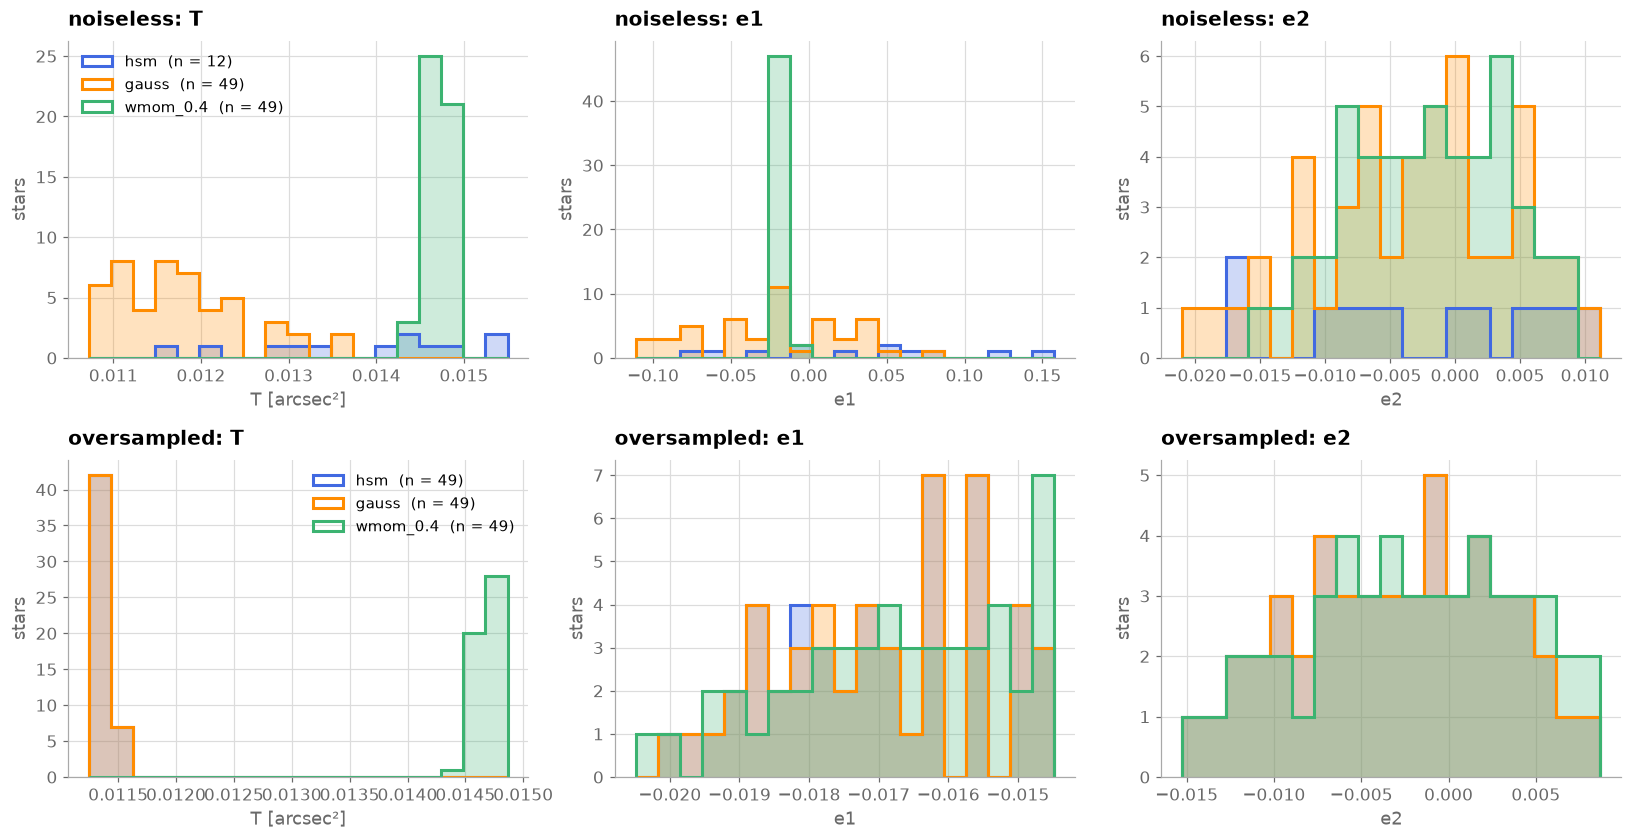

In [6]:
def plot_moments(table, algorithms, images=("noiseless", "oversampled"), colors=COLORS):
    fig, axes = plt.subplots(len(images), 3, figsize=(15, 3.9 * len(images)), squeeze=False)
    for i, image in enumerate(images):
        rows = table[table["image"] == image]
        for j, (q, label) in enumerate(QUANTITIES.items()):
            ax = axes[i, j]
            values = {a: np.asarray(good(rows, algorithm=a)[q]) for a in algorithms}
            pooled = np.concatenate([v for v in values.values() if len(v)])
            bins = np.linspace(pooled.min(), pooled.max(), 20)
            for a, v in values.items():
                if len(v):
                    ax.hist(v, bins=bins, color=colors[a], alpha=0.25)
                    ax.hist(v, bins=bins, color=colors[a], histtype="step", lw=2,
                            label=f"{a}  (n = {len(v)})")
            ax.set(title=f"{image}: {q}", xlabel=label, ylabel="stars")
        axes[i, 0].legend()
    fig.tight_layout()
    plt.show()


plot_moments(res.table, ALGS)

`summary("moments")` gives the mean, the star-to-star standard deviation (`_std`) and the
error on the mean (`_err`) per image and algorithm, with the number of stars used (`n`) and
of failed measurements (`n_flagged`).

In [7]:
fmt(res.summary("moments")["image", "algorithm", "n", "n_flagged", "T_mean", "T_std",
                           "e1_mean", "e2_mean"])

/tmp/ipykernel_225127/1894627341.py:22: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


image,algorithm,n,n_flagged,T_mean,T_std,e1_mean,e2_mean
str11,str8,int64,int64,float64,float64,float64,float64
noiseless,gauss,49,0,0.01176,7.353e-04,-0.02194,-0.003126
noiseless,hsm,12,37,0.01386,0.00127,0.02939,-0.002395
noiseless,wmom_0.4,49,0,0.0147,1.194e-04,-0.01739,-0.002128
oversampled,gauss,49,0,0.01137,6.716e-05,-0.01695,-0.002768
oversampled,hsm,49,0,0.01137,6.732e-05,-0.01696,-0.002767
oversampled,wmom_0.4,49,0,0.0147,1.137e-04,-0.01672,-0.002122


### Changing what is measured

- `set_algorithms(algorithms, wmom_fwhm)`: any of `"hsm"` (GalSim adaptive moments), `"am"`
  (ngmix adaptive moments), `"gauss"` (ngmix elliptical Gaussian fit) and `"wmom"` (moments
  with a fixed circular Gaussian weight of FWHM `wmom_fwhm` arcsec at the star position).
  Several FWHMs give one `wmom_<fwhm>` entry each.
- `set_images(images, oversample, include_pixel)`: any of `"noisy"` (the stamp from the
  simulated image), `"noiseless"` and `"oversampled"`; the oversampling factor; and whether
  the oversampled image includes the pixel response.
- `select(scas, obs)`: only some SCAs or observations.

`wmom` measures through a weight of fixed size, so its `T` is a different quantity for each
FWHM: compare `wmom` values only at the same FWHM. Below: the same stars with three weights,
oversampled images.

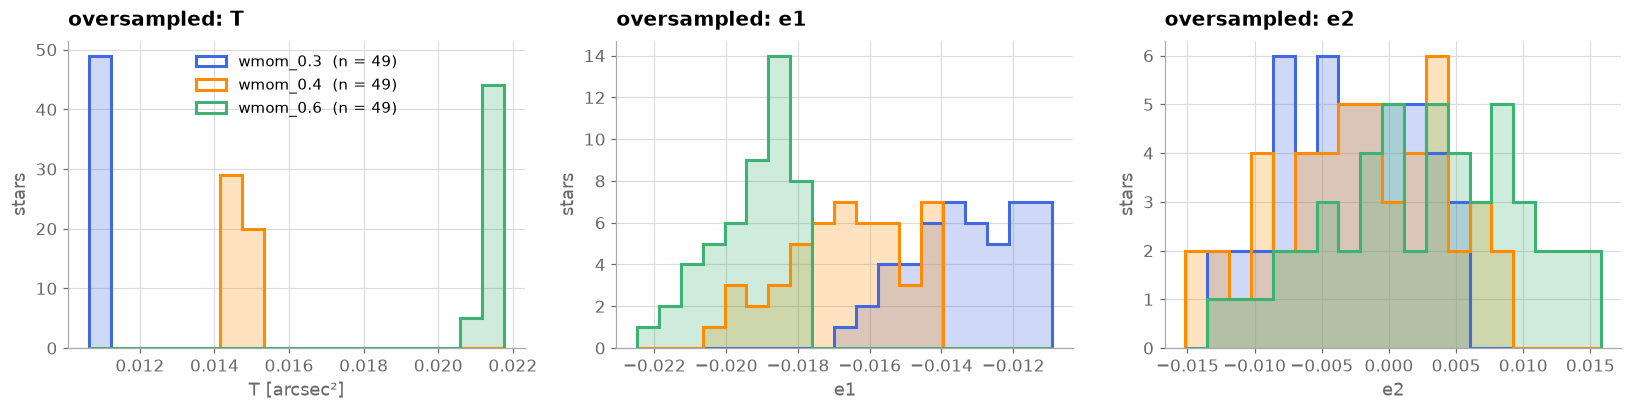

In [8]:
mv = MomentsValidation({"base": sim})
mv.set_algorithms(["wmom"], wmom_fwhm=[0.3, 0.4, 0.6])
mv.set_images(["oversampled"])
res_fwhm = mv.run()

labels = ["wmom_0.3", "wmom_0.4", "wmom_0.6"]
plot_moments(res_fwhm.table, labels, images=["oversampled"],
             colors=dict(zip(labels, COLOR_CYCLE)))

## 2. Measuring a single image

`measure_star(star, algorithm)` measures one Piff `Star`, and `make_star(image, position,
weight)` turns any GalSim image into one: a simulated stamp or a truth image. 
The position is where the measurement starts (`wmom`: where its weight is
centered), in the image's pixel coordinates.

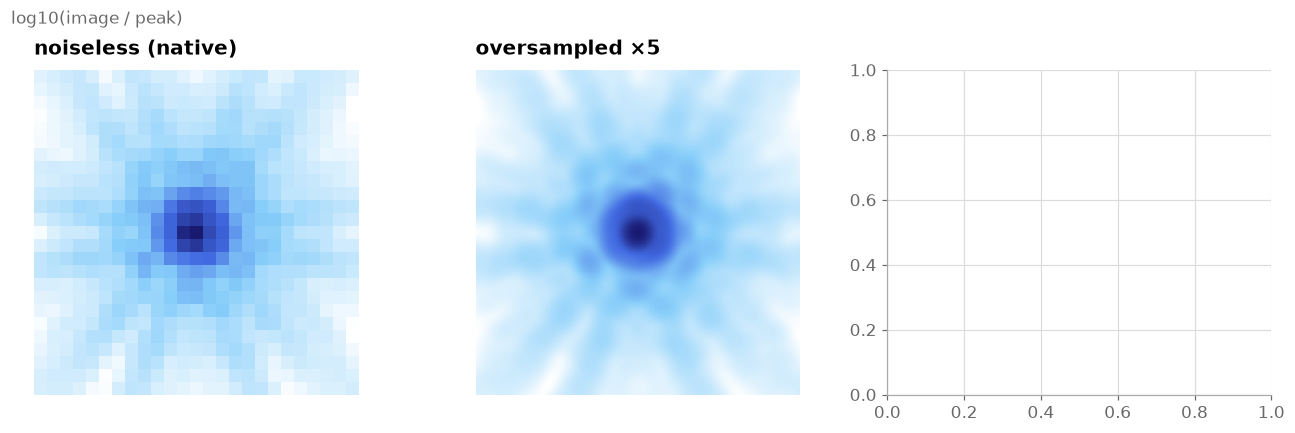

/tmp/ipykernel_225127/1894627341.py:22: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


image,algorithm,T [arcsec²],e1,e2,flag
str18,str5,float64,float64,float64,int64
noiseless (native),hsm,nan,nan,nan,7
noiseless (native),am,nan,nan,nan,1
noiseless (native),gauss,0.0114,0.03235,-0.01111,0
noiseless (native),wmom,0.01482,-0.01682,-0.005468,0
oversampled ×5,hsm,0.01147,-0.01993,-0.005862,0
oversampled ×5,am,0.01146,-0.01993,-0.005869,0
oversampled ×5,gauss,0.01146,-0.01992,-0.005862,0
oversampled ×5,wmom,0.01486,-0.02049,-0.005388,0


In [ ]:
stars, rows = sim.stars(sca=1)                   # Piff stars cut from the simulated image
star = stars[0]
noiseless = make_star(sim.render_stamp(0), star.image_pos, star.weight)
fine = sim.truth_psf(sca=1, obs=0, star_id=0, oversample=5)
oversampled = make_star(fine, fine.true_center)

images = {"noiseless (native)": noiseless, "oversampled ×5": oversampled}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, s) in zip(axes, images.items()):
    a = s.image.array
    ax.imshow(np.log10(np.maximum(a / a.max(), 1e-4)), origin="lower", cmap=STAR_CMAP)
    ax.set_title(name)
    ax.axis("off")
fig.suptitle("log10(image / peak)", x=0.02, ha="left", color=MUTED, fontsize=11)
fig.tight_layout()
plt.show()

rows = []
for name, s in images.items():
    for alg in ("hsm", "am", "gauss", "wmom"):
        m = measure_star(s, alg, weight_fwhm=0.4)
        rows.append({"image": name, "algorithm": alg, "T [arcsec²]": m["T"], "e1": m["e1"],
                     "e2": m["e2"], "flag": m["flag"]})
fmt(Table(rows=rows))

## 3. Native pixels vs the oversampled image

The same star measured on the native pixels and on the oversampled image, with the same
algorithm: each point is one star of section 1. `res.bias()` returns these pairs per star
(`dT_T` = (T_native − T_oversampled) / T_oversampled, `de1`, `de2`), and `summary("bias")`
averages them.

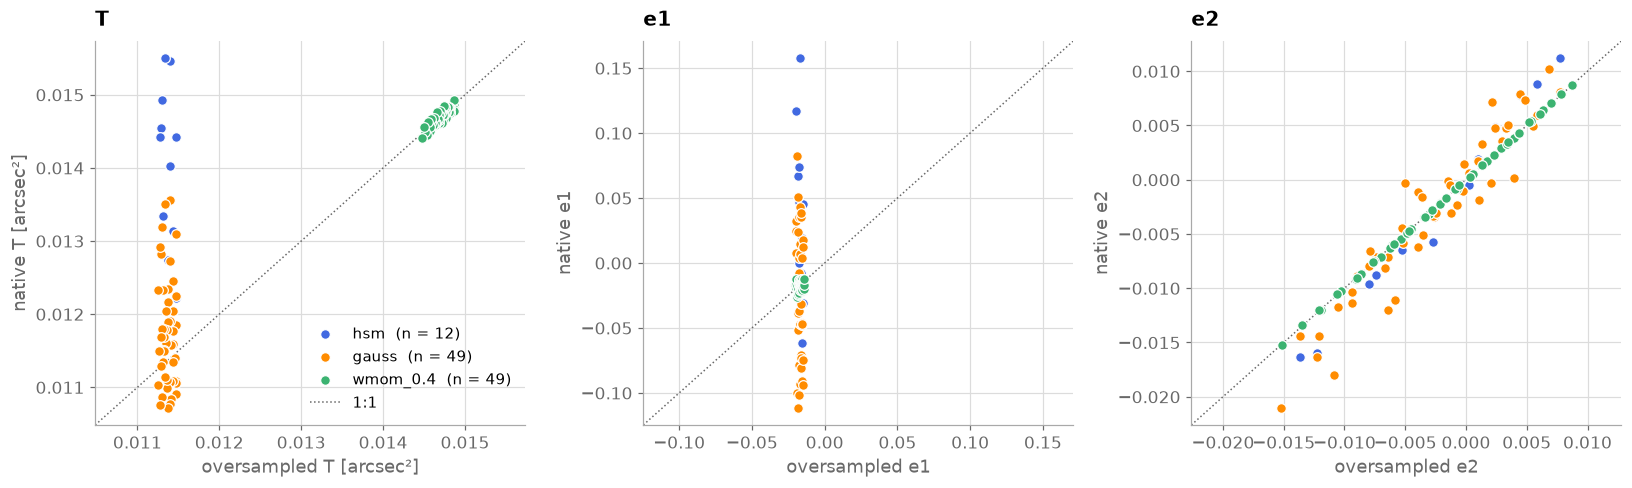

/tmp/ipykernel_225127/1894627341.py:22: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


algorithm,n,n_flagged,dT_T_mean,dT_T_std,de1_mean,de2_mean
str8,int64,int64,float64,float64,float64,float64
gauss,49,0,0.03427,0.06527,-0.004985,-3.579e-04
hsm,12,37,0.2192,0.1131,0.04607,-8.766e-05
wmom_0.4,49,0,-7.931e-05,0.003817,-6.753e-04,-5.752e-06


In [10]:
pairs = res.bias()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (q, label) in zip(axes, QUANTITIES.items()):
    for a in ALGS:
        r = good(pairs, algorithm=a)
        ax.scatter(r[q + "_os"], r[q], s=40, color=COLORS[a], edgecolor=BACKGROUND,
                   lw=0.8, label=f"{a}  (n = {len(r)})", zorder=3)
    one_to_one(ax)
    ax.set(title=q, xlabel=f"oversampled {label}", ylabel=f"native {label}")
axes[0].legend()
fig.tight_layout()
plt.show()

fmt(res.summary("bias")["algorithm", "n", "n_flagged", "dT_T_mean", "dT_T_std", "de1_mean",
                        "de2_mean"])

The result also has ready-made plots: `plot_bias` (the mean differences above),
`plot_recovery`, `plot_vs_phase` and `plot_vs_snr` (see `docs/moments.md`). For example:

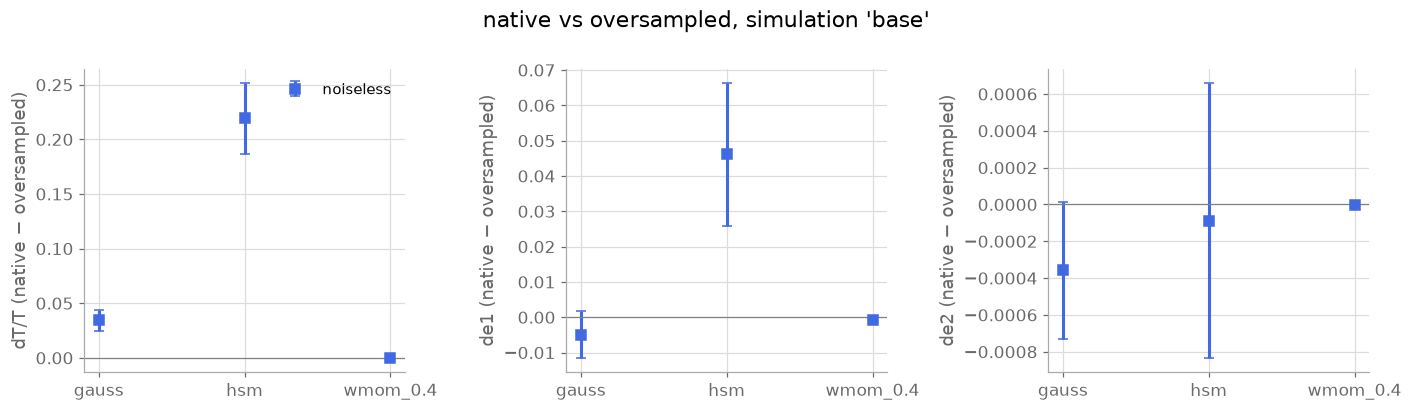

In [11]:
res.plot_bias(images="noiseless");

## 4. Comparing simulations: measured vs injected PSF errors

To see how well a PSF error is measured, compare a simulation with the error to one without.
Simulations with the same seed have the same stars (positions, magnitudes, noise), so they
are compared star by star. Give `MomentsValidation` several simulations and name the
reference:

`MomentsValidation({"base": ..., "defocus": ..., "shear": ...}, reference="base")`

`res.differences()` then gives, for every star, the **measured error** (each simulation −
the reference, same image and algorithm: `dT_T`, `de1`, `de2`) and the **injected error** of
the same star, measured with HSM on the oversampled images (`dT_T_hsm_os`, `de1_hsm_os`, ...).
The injected error is not the nominal value set in the simulation, because the errors act
on the optics before the pixel.

In [12]:
defocus = make_sim()
defocus.set_zernikes({4: 0.05})                  # extra defocus, waves
shear = make_sim()
shear.add_shear(g1=0.01)                         # shear of the optical PSF
sims4 = {"base": make_sim().run(), "defocus": defocus.run(), "shear": shear.run()}
res4 = measure(sims4)

d = res4.summary("differences")
fmt(d[d["image"] == "noiseless"]["sim", "algorithm", "n", "dT_T_mean", "dT_T_hsm_os_mean",
                                 "de1_mean", "de1_hsm_os_mean"])

/tmp/ipykernel_225127/1894627341.py:22: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


sim,algorithm,n,dT_T_mean,dT_T_hsm_os_mean,de1_mean,de1_hsm_os_mean
str7,str8,int64,float64,float64,float64,float64
defocus,gauss,25,0.01296,0.01351,0.00488,0.004717
defocus,hsm,5,0.01156,0.01536,0.003782,0.004464
defocus,wmom_0.4,25,0.01892,0.01351,0.003909,0.004717
shear,gauss,25,-3.963e-04,-1.558e-04,0.008744,0.01027
shear,hsm,5,-0.001313,-1.568e-04,0.004977,0.01027
shear,wmom_0.4,25,-9.534e-05,-1.558e-04,0.008955,0.01027


Per star: measured against injected error, native noiseless stamps. Left: the size change
from the defocus; right: `e1` from the shear.

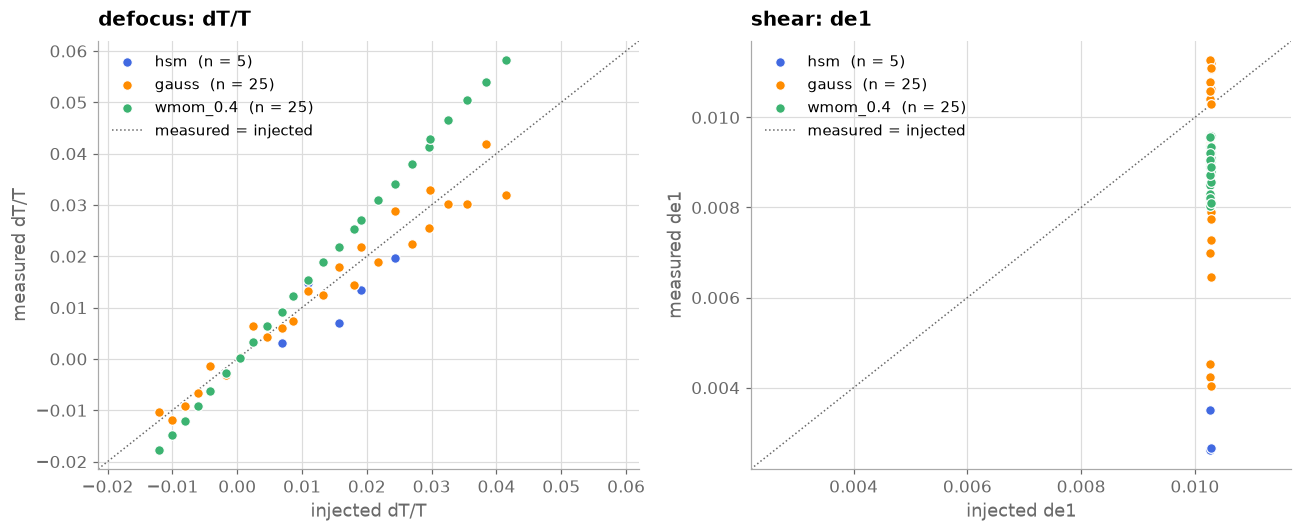

In [13]:
diff4 = res4.differences()
cases = [("defocus", "dT_T", "dT/T"), ("shear", "de1", "de1")]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, q, label) in zip(axes, cases):
    for a in ALGS:
        r = good(diff4, sim=name, image="noiseless", algorithm=a)
        ax.scatter(r[q + "_hsm_os"], r[q], s=40, color=COLORS[a], edgecolor=BACKGROUND, lw=0.8,
                   label=f"{a}  (n = {len(r)})", zorder=3)
    one_to_one(ax, "measured = injected")
    ax.set(title=f"{name}: {label}", xlabel=f"injected {label}", ylabel=f"measured {label}")
    ax.legend()
fig.tight_layout()
plt.show()

## 5. Response to the size of the error

Three scans, each against its own `base` simulation: a dilation of the optical PSF (0.98,
0.99, 1.01, 1.02) for the size, and a shear `g1` or `g2` of the optical PSF (±0.01, ±0.02)
for the shape. For each value: the mean measured error over the stars against the mean
injected error; bars are the star-to-star standard deviation. The gray points are HSM on the
oversampled images, which is the injected error itself; `gauss` and `wmom` are measured on
the native noiseless stamps.

In [14]:
def response(add_error, values, n_stars=25):
    # base + one simulation per value, named "+0.01" etc.
    sims = {"base": make_sim(n_stars).run()}
    for v in values:
        s = make_sim(n_stars)
        add_error(s, v)
        sims[f"{v:+g}"] = s.run()
    return measure(sims)


VALUES = [-0.02, -0.01, 0.01, 0.02]
scans = {"dT_T": response(lambda s, v: s.add_dilation(1 + v), VALUES),
         "de1": response(lambda s, v: s.add_shear(g1=v), VALUES),
         "de2": response(lambda s, v: s.add_shear(g2=v), VALUES)}
TITLES = {"dT_T": "dilation → dT/T", "de1": "shear g1 → e1", "de2": "shear g2 → e2"}

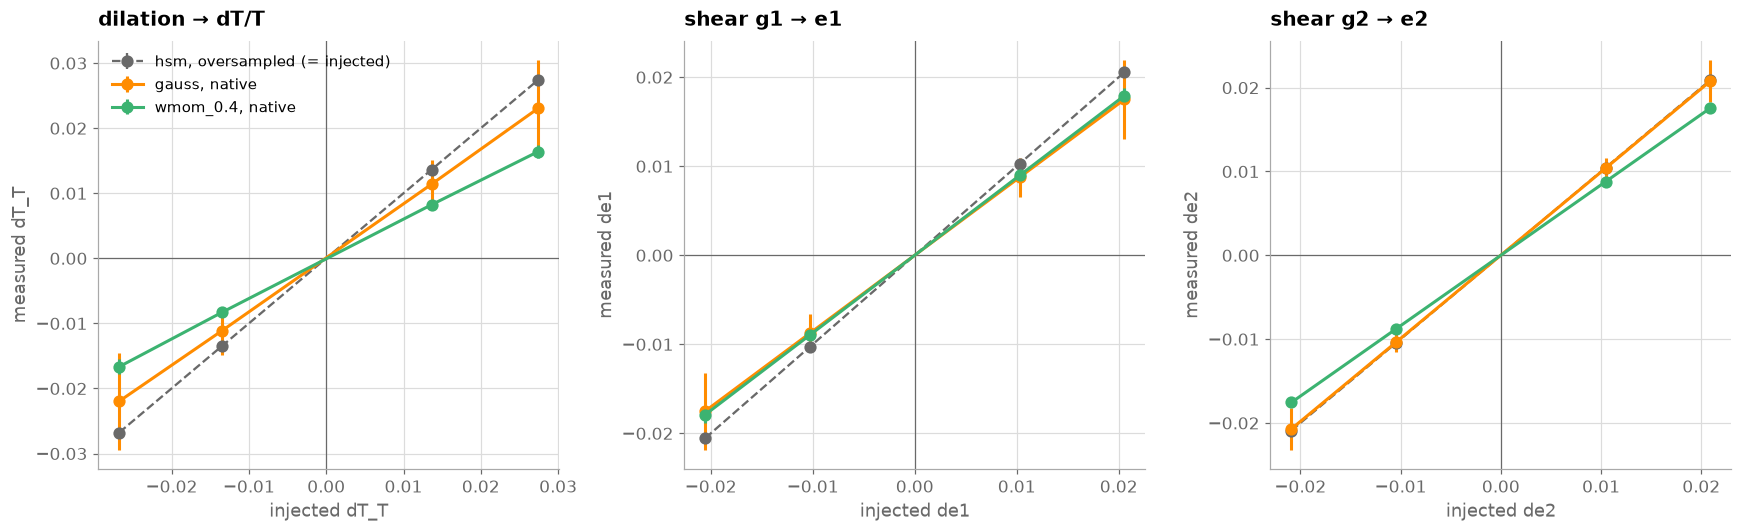

In [15]:
def mean_points(diff, q, algorithm, image):
    # (injected, measured mean, measured std) per simulation, sorted by injected value.
    rows = good(diff, algorithm=algorithm, image=image)
    points = [(np.mean(r[q + "_hsm_os"]), np.mean(r[q]), np.std(r[q]))
              for r in (rows[rows["sim"] == s] for s in set(rows["sim"]))]
    return np.array(sorted(points)).T


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (q, res_q) in zip(axes, scans.items()):
    diff = res_q.differences()
    x, y, s = mean_points(diff, q, "hsm", "oversampled")
    ax.errorbar(x, y, yerr=s, color=REFERENCE, marker="o", ls="--", lw=1.5,
                label="hsm, oversampled (= injected)")
    for a in ("gauss", "wmom_0.4"):
        x, y, s = mean_points(diff, q, a, "noiseless")
        ax.errorbar(x, y, yerr=s, color=COLORS[a], marker="o", label=f"{a}, native")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set(title=TITLES[q], xlabel=f"injected {q}", ylabel=f"measured {q}")
axes[0].legend()
fig.tight_layout()
plt.show()

`hsm` is not shown on the native stamps because it fails on many of them. Number of native
noiseless measurements that failed, per scan (all five simulations of the scan):

In [16]:
counts = []
for q, res_q in scans.items():
    t = res_q.table[res_q.table["image"] == "noiseless"]
    row = {"scan": TITLES[q], "measurements": int(np.sum(t["algorithm"] == "hsm"))}
    for a in ALGS:
        row[f"{a} failed"] = int(np.sum((t["algorithm"] == a) & (t["flag"] != 0)))
    counts.append(row)
Table(rows=counts)

scan,measurements,hsm failed,gauss failed,wmom_0.4 failed
str15,int64,int64,int64,int64
dilation → dT/T,125,97,0,0
shear g1 → e1,125,98,0,0
shear g2 → e2,125,100,0,0


## 6. Sub-pixel phase

Where the star center falls within a pixel (its sub-pixel phase) changes the native image,
and so the measurement. Each point is one star of the scans in section 5: measured / injected
error against the distance of the star center from the pixel center (0 = pixel center,
0.71 = pixel corner), native noiseless stamps. Points outside the plotted range are not shown.

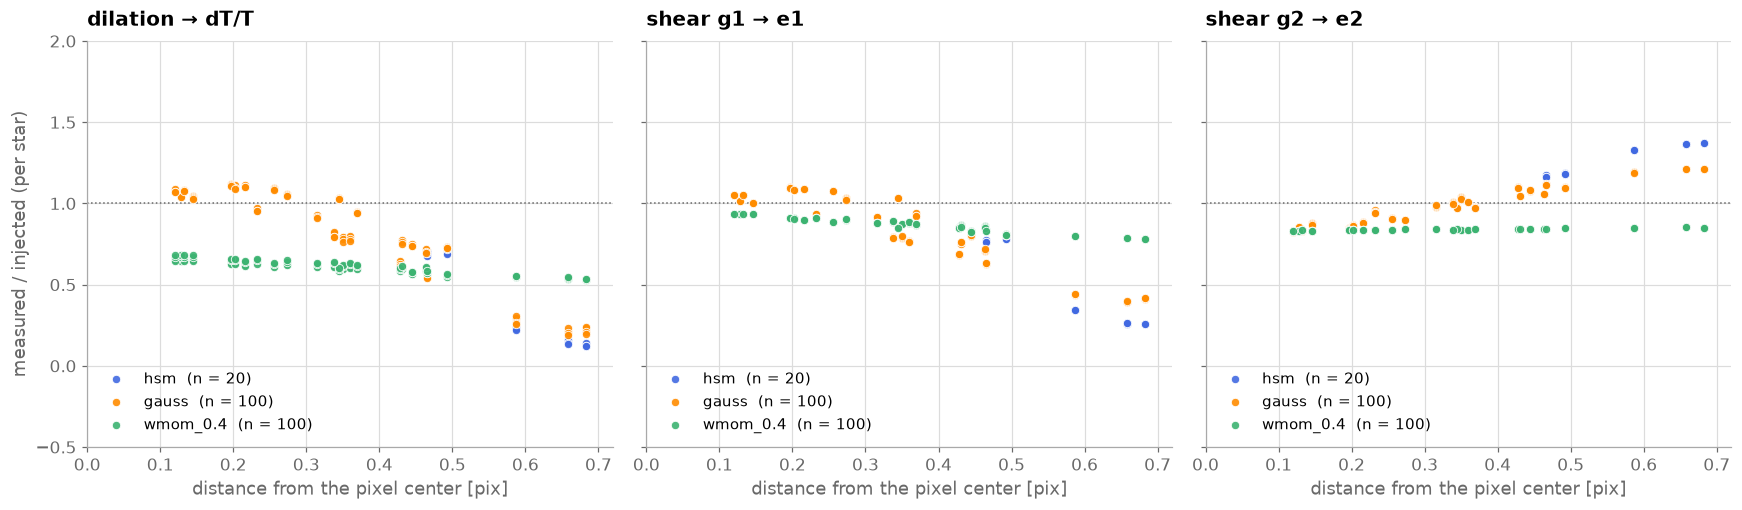

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (q, res_q) in zip(axes, scans.items()):
    diff = res_q.differences()
    for a in ALGS:
        r = good(diff, image="noiseless", algorithm=a)
        ax.scatter(np.hypot(r["phase_x"], r["phase_y"]), r[q] / r[q + "_hsm_os"], s=30,
                   color=COLORS[a], edgecolor=BACKGROUND, lw=0.6, alpha=0.9,
                   label=f"{a}  (n = {len(r)})", zorder=3)
    ax.axhline(1, color=REFERENCE, lw=1, ls=":")
    ax.set(ylim=(-0.5, 2.0), xlim=(0, 0.72), title=TITLES[q],
           xlabel="distance from the pixel center [pix]")
    ax.legend(loc="lower left")
axes[0].set_ylabel("measured / injected (per star)")
fig.tight_layout()
plt.show()

## 7. Centroid errors

Every measurement starts from a position: the catalog position here, the fitted star center
in a PSF fit. What the position does depends on the algorithm:

- `wmom` puts its weight at that position and does not move it, so a wrong position changes
  the measurement directly;
- `hsm` and `gauss` fit their own centroid; the position is only their starting guess.

The tests below measure the noiseless stamps of section 4 about deliberately wrong positions
(the pixels are unchanged; only the position given to `make_star` moves). For `hsm` and
`gauss` they test a wrong starting guess. A wrong fitted center in a PSF fit is a different
case: the model is then drawn at that center, which changes its sub-pixel phase (section 6).

In [18]:
def noiseless_stars(sim):
    stars, rows = sim.stars(sca=1)
    return [make_star(sim.render_stamp(int(r["star_id"])), s.image_pos, s.weight)
            for s, r in zip(stars, rows)], np.array(rows["star_id"])


def measure_shifted(stars, offsets, algorithm):
    # Same pixels; measurement position moved by (dx, dy) native pixels.
    return Table(rows=[measure_star(make_star(s.image, s.image_pos + galsim.PositionD(dx, dy),
                                              s.weight), algorithm, weight_fwhm=0.4)
                       for s, (dx, dy) in zip(stars, offsets)])


def mean(values):
    return np.mean(values) if len(values) else np.nan


CEN_ALGS = {"hsm": "hsm", "gauss": "gauss", "wmom_0.4": "wmom"}   # label → algorithm
base_stars, _ = noiseless_stars(sims4["base"])
n = len(base_stars)

**A shifted position.** Every star measured about a position shifted by `s` pixels along x.
Left and middle: the change in `T` and `e1` relative to the measurement at the true position.
Right: the centroid each algorithm reports, relative to the true position (dotted: the
position it was given).

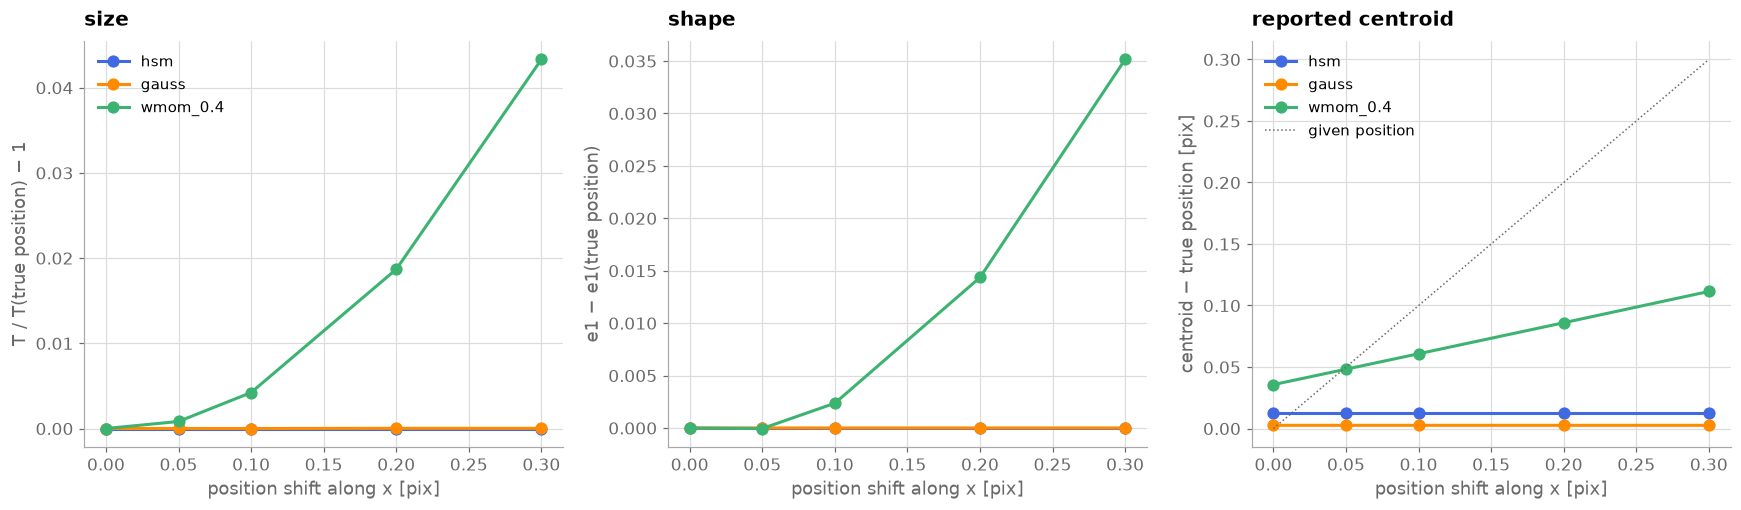

In [19]:
SHIFTS = [0.0, 0.05, 0.1, 0.2, 0.3]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for label, alg in CEN_ALGS.items():
    at_truth = measure_shifted(base_stars, np.zeros((n, 2)), alg)
    dT, de1, cen = [], [], []
    for shift in SHIFTS:
        m = measure_shifted(base_stars, np.tile([shift, 0.0], (n, 1)), alg)
        ok = (m["flag"] == 0) & (at_truth["flag"] == 0)
        dT.append(mean(m["T"][ok] / at_truth["T"][ok] - 1))
        de1.append(mean(m["e1"][ok] - at_truth["e1"][ok]))
        cen.append(mean(m["du"][ok] / galsim.roman.pixel_scale + shift))  # du: from given position
    for ax, values in zip(axes, (dT, de1, cen)):
        ax.plot(SHIFTS, values, "o-", color=COLORS[label], label=label)
axes[2].plot(SHIFTS, SHIFTS, color=REFERENCE, ls=":", lw=1, label="given position")
axes[0].set(title="size", ylabel="T / T(true position) − 1")
axes[1].set(title="shape", ylabel="e1 − e1(true position)")
axes[2].set(title="reported centroid", ylabel="centroid − true position [pix]")
for ax in axes:
    ax.set_xlabel("position shift along x [pix]")
axes[0].legend()
axes[2].legend()
fig.tight_layout()
plt.show()

## 8. Noise and signal-to-noise

Stars from magnitude 18 to 23 with the noise of an L2 image (`set_noise("roman-L2")`): sky,
Poisson, reciprocity failure, dark current and read noise. Nonlinearity and IPC are corrected
in L2 images, so they are left out (`set_noise("roman-L1")` adds them).

Each star is measured on its **noisy** stamp and, for reference, on the same stamp without
noise. The S/N of a star is √(Σ I² / σ²) over its noiseless stamp, σ² the background variance
(column `snr` of the table). `hsm` is left out: it fails on many native stamps (section 5).

In [20]:
builder = make_sim(n_stars=100, seed=3)
builder.set_brightness(mag_range=(18, 23))
builder.set_noise("roman-L2")
noisy_sim = builder.run()

mv_snr = MomentsValidation({"base": noisy_sim})
mv_snr.set_algorithms(["gauss", "wmom"], wmom_fwhm=0.4)
mv_snr.set_images(["noisy", "noiseless"])
res_snr = mv_snr.run()

fmt(res_snr.summary("moments"))

/tmp/ipykernel_225127/1894627341.py:22: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


sim,image,algorithm,n,n_flagged,T_mean,T_std,T_err,sigma_mean,sigma_std,sigma_err,e1_mean,e1_std,e1_err,e2_mean,e2_std,e2_err
str4,str9,str8,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
base,noiseless,gauss,100,0,0.01184,7.600e-04,7.600e-05,0.07685,0.002449,2.449e-04,-0.007593,0.05047,0.005047,-0.002982,0.006578,6.578e-04
base,noiseless,wmom_0.4,100,0,0.0147,1.180e-04,1.180e-05,0.08573,3.432e-04,3.432e-05,-0.01618,0.004282,4.282e-04,-0.002125,0.005789,5.789e-04
base,noisy,gauss,100,0,0.01178,7.751e-04,7.751e-05,0.07664,0.002514,2.514e-04,-0.008271,0.05238,0.005238,-0.001474,0.02419,0.002419
base,noisy,wmom_0.4,100,0,0.01463,2.937e-04,2.937e-05,0.08552,8.664e-04,8.664e-05,-0.01632,0.01219,0.001219,-0.001522,0.01298,0.001298


`T`, `e1` and `e2` of every star against its S/N, measured on the noisy stamps (points). The
line and band are the mean and the star-to-star standard deviation in six S/N bins with the
same number of stars each; the dotted line is the mean of the same stars without noise.

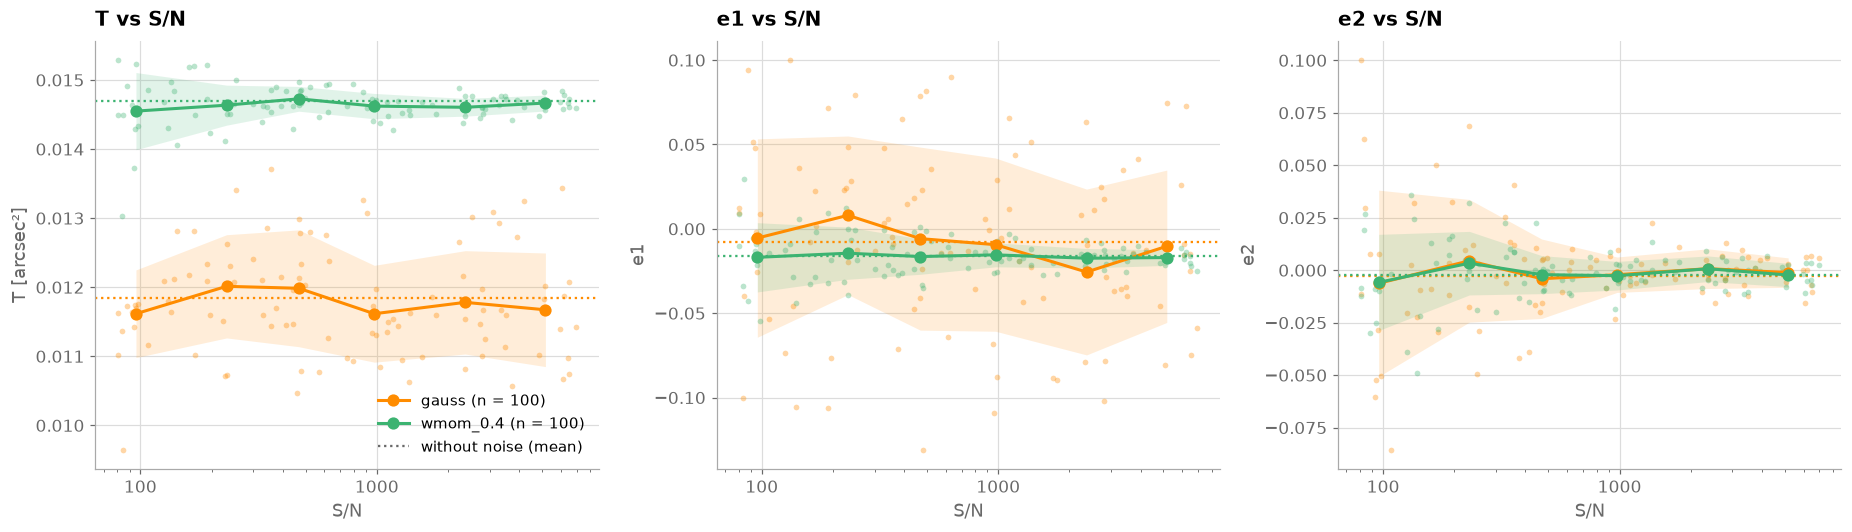

In [21]:
def snr_bins(snr, values, n_bins=6):
    # Equal-count S/N bins: median S/N, mean and standard deviation per bin.
    edges = np.quantile(snr, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(snr, edges[1:-1]), 0, n_bins - 1)
    return np.array([(np.median(snr[idx == b]), values[idx == b].mean(), values[idx == b].std())
                     for b in range(n_bins)]).T


fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for a in ("gauss", "wmom_0.4"):
    noisy = good(res_snr.table, image="noisy", algorithm=a)
    noiseless = good(res_snr.table, image="noiseless", algorithm=a)
    snr = np.asarray(noisy["snr"])
    for ax, q in zip(axes, QUANTITIES):
        values = np.asarray(noisy[q])
        ax.scatter(snr, values, s=14, color=COLORS[a], alpha=0.35, lw=0)
        x, m, s = snr_bins(snr, values)
        ax.plot(x, m, color=COLORS[a], marker="o", label=f"{a} (n = {len(noisy)})")
        ax.fill_between(x, m - s, m + s, color=COLORS[a], alpha=0.15, lw=0)
        ax.axhline(np.mean(noiseless[q]), color=COLORS[a], ls=":", lw=1.5)
for ax, (q, label) in zip(axes, QUANTITIES.items()):
    ax.set(title=f"{q} vs S/N", xlabel="S/N", ylabel=label, xscale="log")
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
axes[0].plot([], [], color=REFERENCE, ls=":", lw=1.5, label="without noise (mean)")
axes[0].legend()
fig.tight_layout()
plt.show()

## 9. Saving

A result can be saved to a folder (`moments.fits` with the table, `config.yaml` with the
configuration and software versions) and reloaded. A `MomentsValidation` whose simulations
were given as saved folders can also be written to YAML and rebuilt. The cells are commented
out so that running the notebook writes nothing.

In [22]:
# Save while running, or afterwards, and reload:
# res = mv.run(save_to="out/moments01")
# res.save("out/moments01")
# from psf_fomo.moments import load_moments
# res = load_moments("out/moments01")

# A configuration file, with the simulations given as saved folders:
# mv = MomentsValidation({"base": "out/sim_base", "defocus": "out/sim_defocus"}, reference="base")
# mv.to_yaml("moments.yaml")
# res = MomentsValidation.from_yaml("moments.yaml").run()